# Проверка модели типа OpenCLIP на тестовых данных

Первый вариант тестовых данных, состоящий из 57 картинок и их описаний. Задача: проверить, будем ли мы по описанию находить нужную картинку (@k)

In [ ]:
!pip install -q open_clip_torch

In [ ]:
from pathlib import Path
import os
import json
import math

import torch
from PIL import Image
import pandas as pd
import open_clip
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
data_dir = Path("/content/drive/MyDrive/Colab Notebooks/data/lostitems-57").absolute()

os.listdir(data_dir)[:5]

['57.jpg', '56.jpg', '55.jpg', '54.jpg', '53.jpg']

In [ ]:
with open(data_dir / "lostitems.json") as f:
    data_info = json.load(f)

list(data_info.keys())[:5]

['1', '2', '3', '4', '5']

Load OpenCLIP model

In [ ]:
# model_name = "hf-hub:apple/MobileCLIP-S2-OpenCLIP"
model_name = "hf-hub:laion/CLIP-ViT-H-14-laion2B-s32B-b79K"

model, preprocess = open_clip.create_model_from_pretrained(model_name, device="cuda")
tokenizer = open_clip.get_tokenizer(model_name)

RuntimeError: Failed initial config/weights load from HF Hub laion/CLIP-ViT-H-14-laion2B-s32B-b79K: Failed to download file (open_clip_config.json) for laion/CLIP-ViT-H-14-laion2B-s32B-b79K. Last error: Invalid URL '/api/resolve-cache/models/laion/CLIP-ViT-H-14-laion2B-s32B-b79K/1c2b8495b28150b8a4922ee1c8edee224c284c0c/open_clip_config.json?%2Flaion%2FCLIP-ViT-H-14-laion2B-s32B-b79K%2Fresolve%2Fmain%2Fopen_clip_config.json=&etag=%22a7e04ce761ac15fc0edd245e5ddc0e88fabdf67a%22': No scheme supplied. Perhaps you meant https:///api/resolve-cache/models/laion/CLIP-ViT-H-14-laion2B-s32B-b79K/1c2b8495b28150b8a4922ee1c8edee224c284c0c/open_clip_config.json?%2Flaion%2FCLIP-ViT-H-14-laion2B-s32B-b79K%2Fresolve%2Fmain%2Fopen_clip_config.json=&etag=%22a7e04ce761ac15fc0edd245e5ddc0e88fabdf67a%22?

In [ ]:
all_indices = [int(k) for k in data_info.keys()]
all_indices.sort()

images = [Image.open(data_dir / f"{i}.jpg") for i in tqdm(all_indices)]
images_tensor = torch.concat([preprocess(image).unsqueeze(0) for image in images], axis=0)

texts_russian = [data_info[str(i)]["russian"] for i in all_indices]
texts_russian_tensor = tokenizer(texts_russian)
texts_english_tensor = tokenizer([data_info[str(i)]["english"] for i in all_indices])

print(images_tensor.shape)
print(texts_russian_tensor.shape)
print(texts_english_tensor.shape)

In [ ]:
images_tensor = images_tensor.to("cuda")
texts_russian_tensor = texts_russian_tensor.to("cuda")
texts_english_tensor = texts_english_tensor.to("cuda")

In [ ]:
batch_size = 4
num_batches = int(math.ceil(images_tensor.shape[0] / batch_size))

text_russian_embeddings = []
text_english_embeddings = []
image_embeddings = []

with torch.no_grad(), torch.amp.autocast("cuda"):
    for batch_index in tqdm(range(num_batches), total=num_batches):
        idx = batch_index * batch_size
        img = images_tensor[idx : idx + batch_size]
        txt_ru = texts_russian_tensor[idx : idx + batch_size]
        txt_en = texts_english_tensor[idx : idx + batch_size]

        image_features = model.encode_image(img).detach()
        image_embeddings.append(image_features)

        text_russian_embeddings.append(model.encode_text(txt_ru).detach())
        text_english_embeddings.append(model.encode_text(txt_en).detach())

  0%|          | 0/15 [00:00<?, ?it/s]

In [ ]:
text_russian_embeddings = torch.concat(text_russian_embeddings, axis=0)
text_english_embeddings = torch.concat(text_english_embeddings, axis=0)
image_embeddings = torch.concat(image_embeddings, axis=0)

image_embeddings.shape, text_russian_embeddings.shape, text_english_embeddings.shape

(torch.Size([57, 1024]), torch.Size([57, 1024]), torch.Size([57, 1024]))

In [ ]:
torch.save(image_embeddings, data_dir / "image_embeddings_laion.pt")
torch.save(text_english_embeddings, data_dir / "text_english_embeddings_laion.pt")
torch.save(text_russian_embeddings, data_dir / "text_russian_embeddings_laion.pt")

## Проверка качества

In [ ]:
image_embeddings = torch.load(data_dir / "image_embeddings_laion.pt")
text_english_embeddings = torch.load(data_dir / "text_english_embeddings_laion.pt")
text_russian_embeddings = torch.load(data_dir / "text_russian_embeddings_laion.pt")

In [ ]:
similarity_russian = text_russian_embeddings @ image_embeddings.T
similarity_english = text_english_embeddings @ image_embeddings.T

In [ ]:
text_russian_embeddings_norm = text_russian_embeddings / text_russian_embeddings.norm(
    dim=-1, keepdim=True
)
text_english_embeddings_norm = text_english_embeddings / text_english_embeddings.norm(
    dim=-1, keepdim=True
)
image_embeddings_norm = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)

similarity_russian_norm = text_russian_embeddings_norm @ image_embeddings_norm.T
similarity_english_norm = text_english_embeddings_norm @ image_embeddings_norm.T

print(similarity_russian_norm.shape)
print(similarity_russian_norm.min(), similarity_russian_norm.max())

torch.Size([57, 57])
tensor(0.0203, device='cuda:0', dtype=torch.float16) tensor(0.3872, device='cuda:0', dtype=torch.float16)


Попробуем по тексту находить подходящую картинку

In [ ]:
def calc_precision_at_k(similarity, k):
    matches = 0
    # Find top matches for first few texts
    for i in range(similarity.shape[0]):
        scores, indices = similarity[i].topk(k)
        scores = scores.tolist()
        indices = indices.tolist()

        if i in indices:
            matches += 1
    return matches / similarity.shape[0]

calc_precision_at_k(similarity_english, k=2)

0.8245614035087719

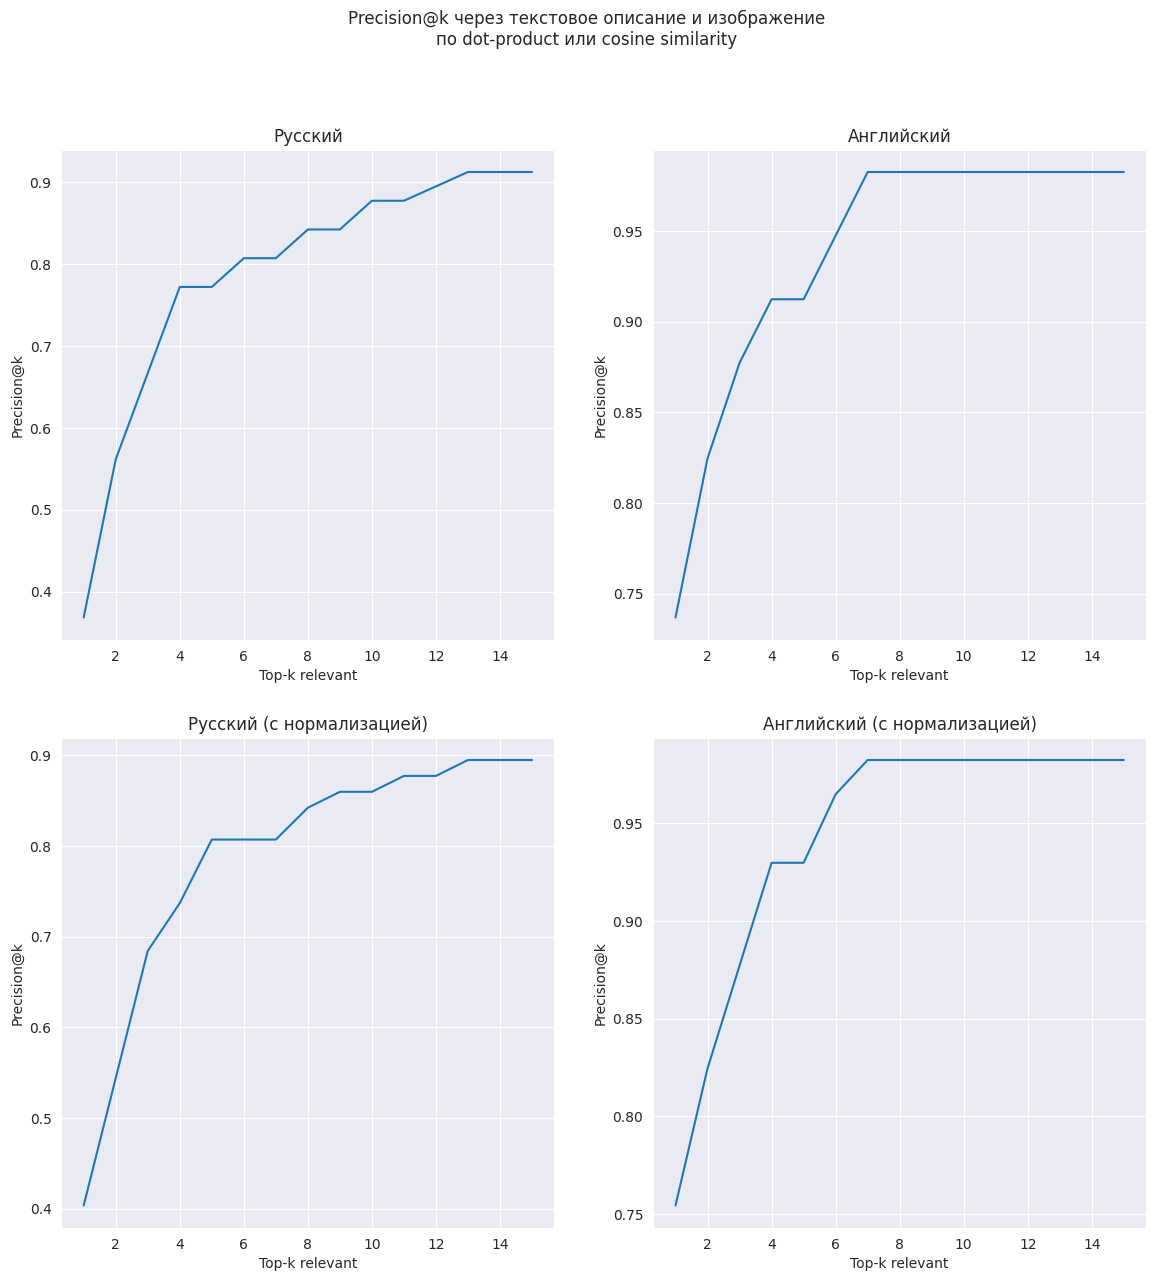

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
ax_flat = [a_ for a in axes for a_ in a]  # just axes as 1d list

fig.suptitle(
    "Precision@k через текстовое описание и изображение\nпо dot-product или cosine similarity"
)


for ax, similarity, suptitle in zip(
    ax_flat,
    [
        similarity_russian,
        similarity_english,
        similarity_russian_norm,
        similarity_english_norm,
    ],
    [
        "Русский",
        "Английский",
        "Русский (с нормализацией)",
        "Английский (с нормализацией)",
    ],
):
    k_range = list(range(1, 16))
    precision_at_k_list = [calc_precision_at_k(similarity, k=k) for k in k_range]

    sns.lineplot(x=k_range, y=precision_at_k_list, ax=ax)
    ax.set_xlabel("Top-k relevant")
    ax.set_ylabel("Precision@k")
    ax.set_title(suptitle)

    fig.savefig(data_dir / "precision_at_k.png")
    fig.savefig(data_dir / "precision_at_k.jpg")

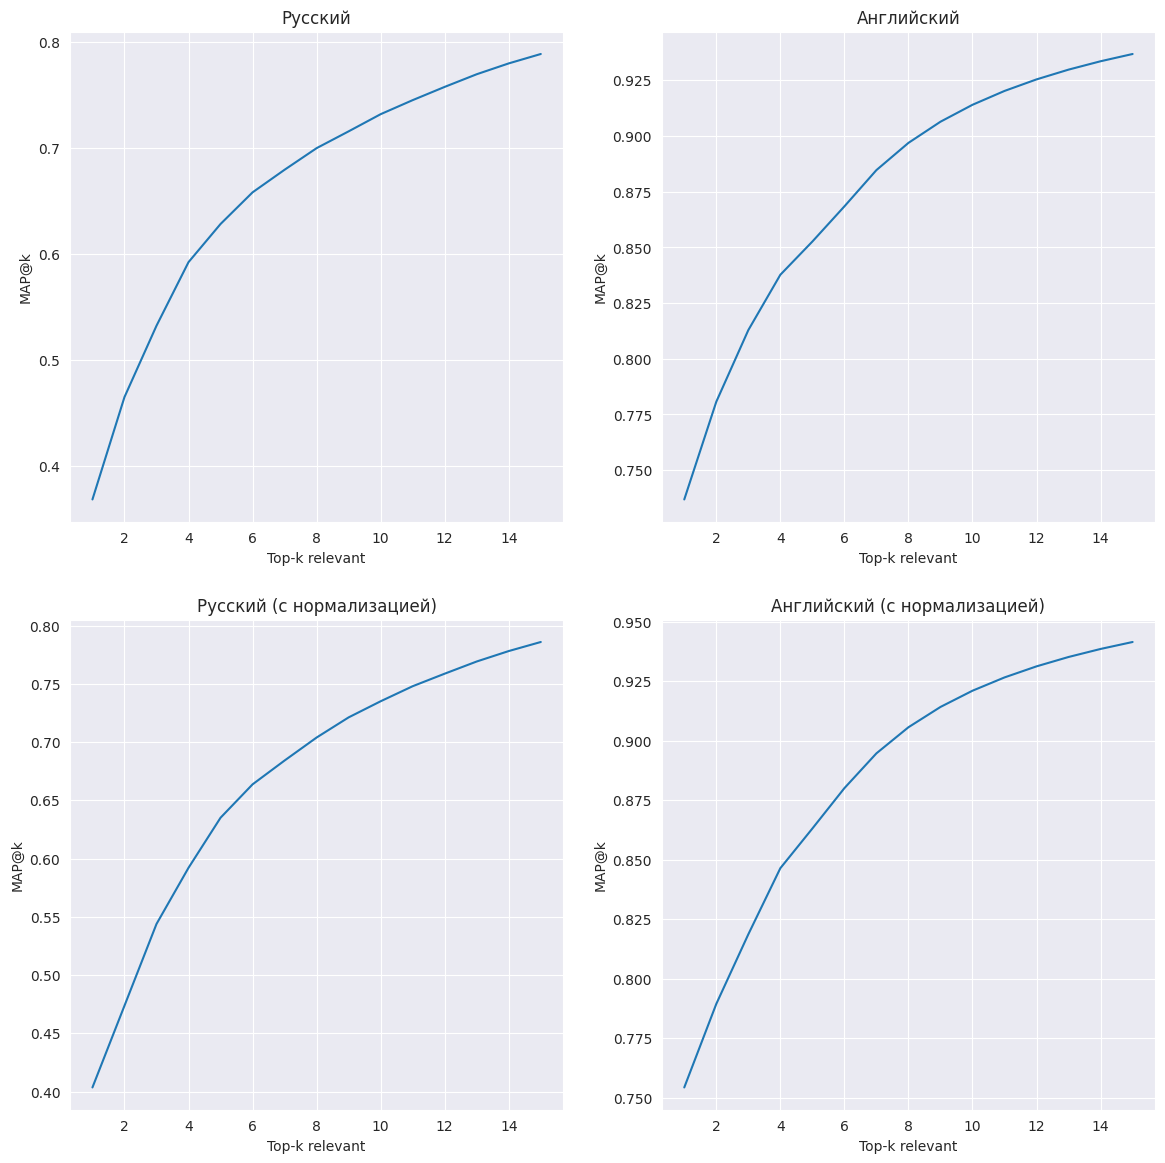

In [ ]:
def calc_mean_average_precision_at_k(similarity, k):
    result = 0
    for k_ in range(1, k + 1):
        result += calc_precision_at_k(similarity, k=k_)
    result /= k
    return result


fig, axes = plt.subplots(2, 2, figsize=(14, 14))
ax_flat = [a_ for a in axes for a_ in a]  # just axes as 1d list

# fig.suptitle(
#     "Precision@k через текстовое описание и изображение\nпо dot-product или cosine similarity"
# )


for ax, similarity, suptitle in zip(
    ax_flat,
    [
        similarity_russian,
        similarity_english,
        similarity_russian_norm,
        similarity_english_norm,
    ],
    [
        "Русский",
        "Английский",
        "Русский (с нормализацией)",
        "Английский (с нормализацией)",
    ],
):
    k_range = list(range(1, 16))
    precision_at_k_list = [
        calc_mean_average_precision_at_k(similarity, k=k) for k in k_range
    ]

    sns.lineplot(x=k_range, y=precision_at_k_list, ax=ax)
    ax.set_xlabel("Top-k relevant")
    ax.set_ylabel("MAP@k")
    ax.set_title(suptitle)

fig.savefig(data_dir / "map_at_k.png")

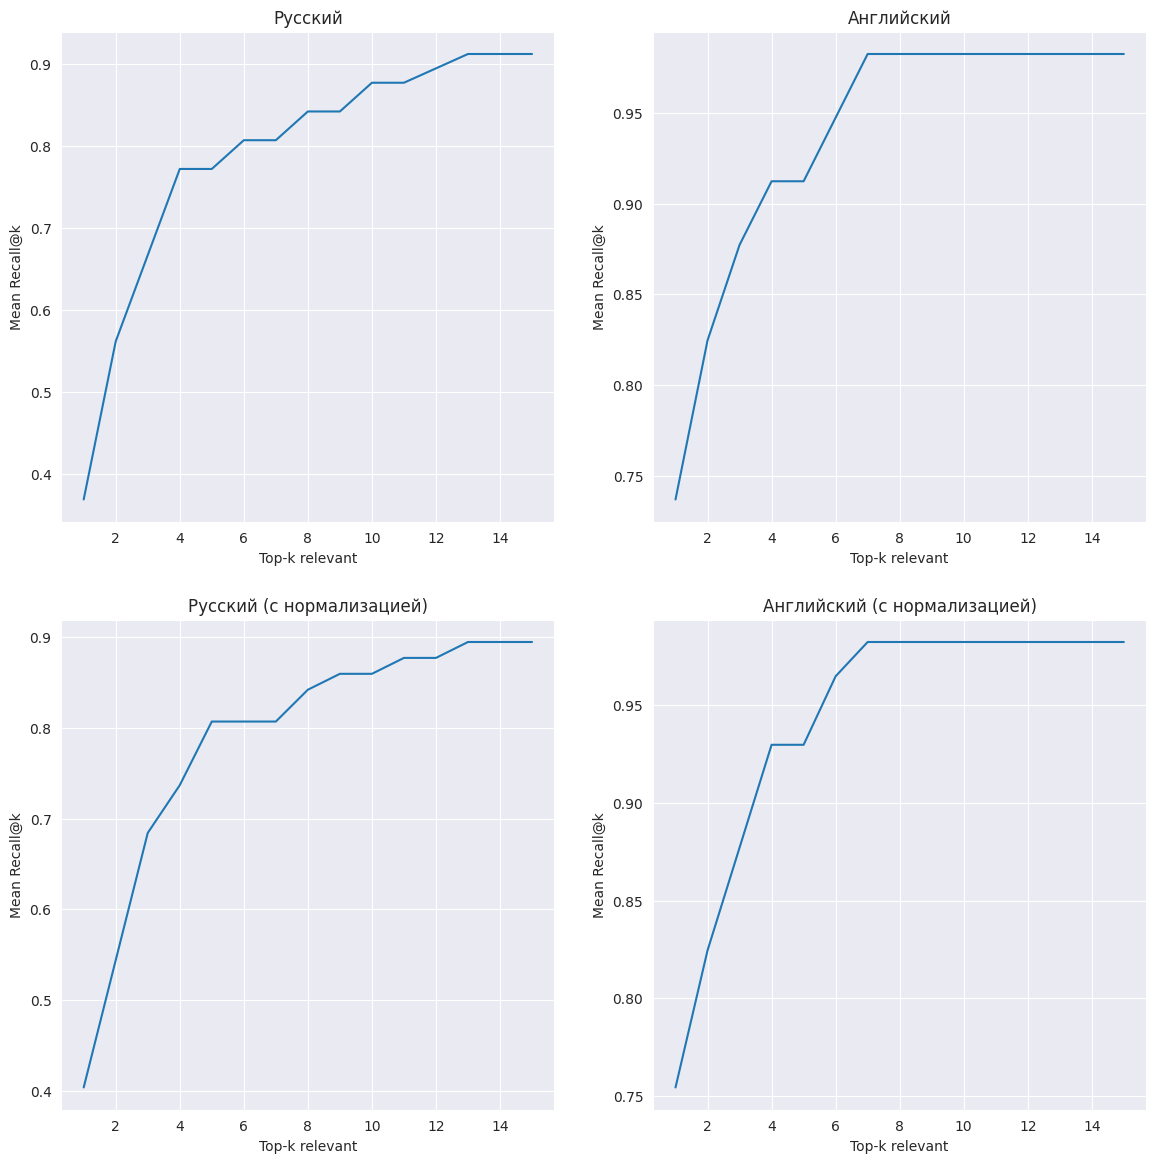

In [ ]:
import torch


def mean_recall_at_k(similarity: torch.Tensor, k: int) -> float:
    """
    Calculates the Mean Recall @ k for a given similarity matrix.

    Args:
        similarity: A torch tensor of shape (N, N) representing the similarity between N items.
        k: The number of top-ranked items to consider for recall.

    Returns:
        The Mean Recall @ k as a float.
    """

    n = similarity.shape[0]
    recall_sum = 0.0

    for i in range(n):
        # Get similarity scores for the i-th item
        scores = similarity[i]

        # Rank the items based on similarity scores (excluding the item itself).  Use argsort to get indices.
        ranked_indices = torch.argsort(scores, descending=True)

        # Consider the top k ranked items. We don't exclude the item itself in the argsort operation, so take k+1 if i is among topk, otherwise k.
        topk_indices = ranked_indices[:k]

        # Check if the i-th item (the ground truth) is in the top k ranked items (excluding itself).  If it is, it's a "hit".
        # The "ground truth" is that item i should be retrieved when querying with item i.

        if i in topk_indices:
            recall = 1.0
        else:
            recall = 0.0

        recall_sum += recall

    # Calculate the Mean Recall @ k
    mean_recall = recall_sum / n
    return mean_recall


fig, axes = plt.subplots(2, 2, figsize=(14, 14))
ax_flat = [a_ for a in axes for a_ in a]  # just axes as 1d list

# fig.suptitle(
#     "Precision@k через текстовое описание и изображение\nпо dot-product или cosine similarity"
# )


for ax, similarity, suptitle in zip(
    ax_flat,
    [
        similarity_russian,
        similarity_english,
        similarity_russian_norm,
        similarity_english_norm,
    ],
    [
        "Русский",
        "Английский",
        "Русский (с нормализацией)",
        "Английский (с нормализацией)",
    ],
):
    k_range = list(range(1, 16))
    precision_at_k_list = [mean_recall_at_k(similarity, k=k) for k in k_range]

    sns.lineplot(x=k_range, y=precision_at_k_list, ax=ax)
    ax.set_xlabel("Top-k relevant")
    ax.set_ylabel("Mean Recall@k")
    ax.set_title(suptitle)

fig.savefig(data_dir / "mean_recall_at_k.jpg")